# Ames Housing Price Prediction: End-to-End Leakage-Free Preprocessing & Feature Engineering Pipeline (v4)

---

## Project Overview & Methodological Evolution (v3 $\to$ v4)

This notebook delivers the enterprise-grade, mathematically rigorous data preprocessing, domain feature engineering, and predictive feature selection pipeline for the **Ames Housing Price Prediction** project.

### The Critical Methodological Upgrade: Zero Data Leakage
In previous iterations (v3), certain learned statistical operations—specifically neighborhood-grouped median imputation for `LotFrontage`, modal imputation for `Electrical`, Pearson correlation rankings, and Mutual Information feature selection—were performed across the entire dataset before partitioning. While common in exploratory prototypes, this allowed test set information to subtly leak into the data preparation stages.

**In Version 4.0, we establish a strict Data Boundary at Step Zero:**
1. **Immediate 80/20 Train-Test Split**: The dataset is partitioned immediately following ingestion and schema verification. The 20% test partition ($n = 292$) is strictly quarantined as unseen holdout data.
2. **Leakage-Free Imputation**:
   - Deterministic structural absences (no pool, no garage, etc.) are converted to `'None'` or `0` via domain rules.
   - Neighborhood medians for `LotFrontage` and the modal class for `Electrical` are learned **strictly from the training partition** and applied downstream to the test partition with global fallbacks.
3. **Training-Only Predictive Feature Selection**:
   - Pearson correlation against `SalePrice` and Mutual Information regression are computed **exclusively on the training partition** (`X_train` vs `y_train`).
   - Multicollinearity and Cramér's V association pruning are evaluated purely on training distributions.
4. **Isolated ColumnTransformer**: Standard scaling and category encodings are fitted solely on `X_train_selected` and applied to `X_test_selected`.
5. **Cross-Validation Pipeline Architecture**: Detailed implementation showing how feature engineering and selection are embedded inside CV folds for zero-leakage model selection.

```
OLD WORKFLOW (v3 - Minor Data Leakage):
[Raw Data] -> [Global Imputation (LotFrontage/Electrical)] -> [Global Feature Selection (r & MI)] -> [Train/Test Split] -> [ColumnTransformer]

NEW WORKFLOW (v4 - 100% Strict Zero Leakage):
[Raw Data] -> [TRAIN/TEST SPLIT (Step 0 Boundary)]
                   |--> [Train Set (80%)] -> Learn Imputers, Statistics, Feature Selection, Scalers & Encoders
                   |--> [Test Set (20%)]  -> Transform with Learned Parameters (Unseen Evaluation)
```

# Section 1: Dataset Ingestion & Structural Inspection

## 1.1 Import Core Data Science & Machine Learning Libraries
- **Purpose**: Load essential Python packages for data manipulation, statistical analysis, visualization, and Scikit-Learn transformers.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib

from sklearn.model_selection import train_test_split
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import mutual_info_regression
from scipy.stats import chi2_contingency

# Configure visualization styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_palette('deep')
%matplotlib inline

print("Core libraries imported successfully.")

Core libraries imported successfully.


## 1.2 Ingest Raw Ames Housing Dataset
- **Purpose**: Read `dataset.csv` into a Pandas DataFrame and inspect initial records.

In [2]:
df = pd.read_csv("dataset.csv")
print(f"Dataset successfully loaded. Dimensions: {df.shape[0]} rows, {df.shape[1]} columns.")
df.head()

Dataset successfully loaded. Dimensions: 1460 rows, 81 columns.


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 1.3 Audit Dataset Dimensions & Column Schema
- **Purpose**: Retrieve total feature count and inspect data types across the raw feature matrix.

In [3]:
print("Total observations:", df.shape[0])
print("Total columns:", df.shape[1])
print()
print("Column schema overview:")
print(df.dtypes.value_counts())

Total observations: 1460
Total columns: 81

Column schema overview:
str        43
int64      35
float64     3
Name: count, dtype: int64


## 1.4 Separate Features ($X$), Continuous Target ($y$), and Record Identifier (`Id`)
- **Purpose**: Isolate the target response `SalePrice` and primary key `Id` from predictor candidates before partitioning.
- **Traceability Note**: Retaining `Id` ensures exact row tracking across train and test partitions.

In [4]:
# Primary key isolation for traceability
record_ids = df["Id"].copy()

# Feature matrix (excluding target and ID)
X_raw = df.drop(columns=["SalePrice", "Id"], errors="ignore").copy()

# Target vector
y_raw = df["SalePrice"].copy()

print(f"Features Matrix (X_raw): {X_raw.shape}")
print(f"Target Vector (y_raw): {y_raw.shape}")
print(f"Primary Keys (record_ids): {record_ids.shape}")

Features Matrix (X_raw): (1460, 79)
Target Vector (y_raw): (1460,)
Primary Keys (record_ids): (1460,)


# Section 2: Strict Data Boundary — Train / Test Partitioning

## 2.1 The Methodological Imperative: Partitioning at Step Zero
- **Core Principle**: A holdout test set represents unseen future observations. It must NEVER participate in calculating:
  1. Imputation statistics (medians, modes, means).
  2. Predictive feature rankings (correlations, mutual information).
  3. Redundancy thresholds and multicollinearity pruning.
  4. Feature normalization scales ($\mu, \sigma$) or categorical vocabulary mappings.
- **Action**: Perform an 80/20 train/test split immediately using `random_state=42`.

In [5]:
X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
    X_raw,
    y_raw,
    record_ids,
    test_size=0.20,
    random_state=42
)

print("=" * 50)
print("TRAIN / TEST PARTITION SIZES")
print("=" * 50)
print(f"Training Features (X_train): {X_train.shape[0]} rows (80.0%), {X_train.shape[1]} columns")
print(f"Testing Features  (X_test):  {X_test.shape[0]} rows (20.0%), {X_test.shape[1]} columns")
print(f"Training Target   (y_train): {y_train.shape[0]} rows")
print(f"Testing Target    (y_test):  {y_test.shape[0]} rows")

# Partition disjointness verification
assert len(set(id_train).intersection(set(id_test))) == 0, "Error: Overlap detected between train and test IDs!"
print()
print("[VERIFIED] Train and test partitions are strictly disjoint with zero record overlap.")

TRAIN / TEST PARTITION SIZES
Training Features (X_train): 1168 rows (80.0%), 79 columns
Testing Features  (X_test):  292 rows (20.0%), 79 columns
Training Target   (y_train): 1168 rows
Testing Target    (y_test):  292 rows

[VERIFIED] Train and test partitions are strictly disjoint with zero record overlap.


# Section 3: Missing Value Analysis & Leakage-Safe Imputation

## 3.1 Missing Value Profiling on Training Data
- **Purpose**: Audit null distributions within `X_train` to distinguish between structural absence (amenity not present) and genuine missingness.

In [6]:
train_missing = X_train.isnull().sum()
train_missing = train_missing[train_missing > 0].sort_values(ascending=False)

train_missing_pct = (train_missing / len(X_train)) * 100

missing_profile = pd.DataFrame({
    "Missing Count": train_missing,
    "Percentage (%)": train_missing_pct
})

print(f"Features with missing values in X_train: {len(missing_profile)}")
missing_profile

Features with missing values in X_train: 19

,Missing Count,Percentage (%)
PoolQC,1162,99.486301
MiscFeature,1122,96.061644
Alley,1094,93.664384
Fence,935,80.051370
MasVnrType,683,58.476027
FireplaceQu,547,46.832192
LotFrontage,217,18.578767
GarageType,64,5.479452
GarageYrBlt,64,5.479452
GarageFinish,64,5.479452


## 3.2 Visualize Missing Feature Percentages
- **Purpose**: Graphical profile of incomplete features within the training partition.

C:\Users\ASUS\AppData\Local\Temp\ipykernel_26320\4022037353.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


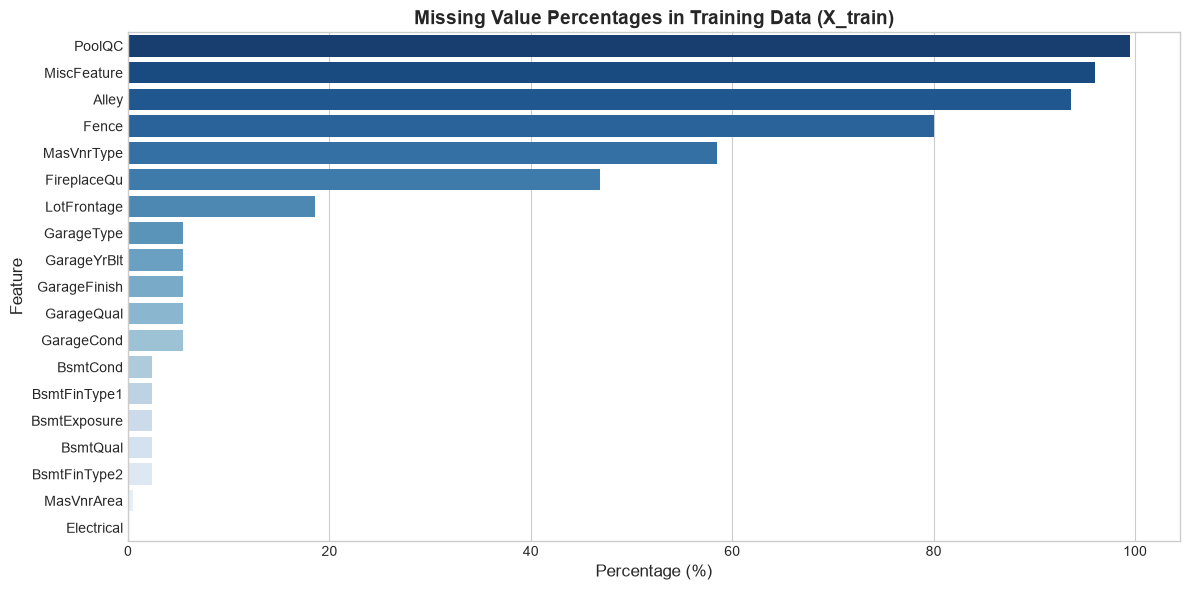

In [7]:
plt.figure(figsize=(12, 6))
sns.barplot(
    x=missing_profile["Percentage (%)"],
    y=missing_profile.index,
    palette="Blues_r"
)
plt.title("Missing Value Percentages in Training Data (X_train)", fontsize=14, fontweight="bold")
plt.xlabel("Percentage (%)", fontsize=12)
plt.ylabel("Feature", fontsize=12)
plt.tight_layout()
plt.show()

## 3.3 Domain-Aware Structural Imputation: Categorical Amenities $\to$ `'None'`
- **Domain Insight**: In the Ames real estate dataset, an `NA` for amenities indicates physical absence (no pool, no alley, no garage, no basement), rather than corrupted data.
- **Action**: Replace `NaN` with `'None'` across affected categorical columns for both `X_train` and `X_test`.
- **Leakage Status**: **Zero Leakage** (deterministic real estate ontology; no learned distribution parameter).

In [8]:
none_cols = [
    "PoolQC",
    "MiscFeature",
    "Alley",
    "Fence",
    "MasVnrType",
    "FireplaceQu",
    "GarageType",
    "GarageFinish",
    "GarageQual",
    "GarageCond",
    "BsmtExposure",
    "BsmtFinType1",
    "BsmtFinType2",
    "BsmtQual",
    "BsmtCond"
]

for col in none_cols:
    X_train[col] = X_train[col].fillna("None")
    X_test[col] = X_test[col].fillna("None")

print(f"Successfully imputed 'None' across {len(none_cols)} categorical amenity features in X_train and X_test.")

Successfully imputed 'None' across 15 categorical amenity features in X_train and X_test.


## 3.4 Domain-Aware Structural Imputation: Numerical Amenities $\to$ `0`
- **Domain Insight**: If a property lacks a garage or basement, dimensional metrics (area, capacity, year built) are physically zero.
- **Action**: Replace `NaN` with `0` across affected numerical columns for both `X_train` and `X_test`.
- **Leakage Status**: **Zero Leakage** (deterministic physical fact).

In [9]:
zero_cols = [
    "GarageYrBlt",
    "GarageArea",
    "GarageCars",
    "BsmtFinSF1",
    "BsmtFinSF2",
    "BsmtUnfSF",
    "TotalBsmtSF",
    "BsmtFullBath",
    "BsmtHalfBath",
    "MasVnrArea"
]

for col in zero_cols:
    X_train[col] = X_train[col].fillna(0)
    X_test[col] = X_test[col].fillna(0)

print(f"Successfully imputed 0 across {len(zero_cols)} numerical measurement features in X_train and X_test.")

Successfully imputed 0 across 10 numerical measurement features in X_train and X_test.


## 3.5 Leakage-Safe Imputation for `LotFrontage`: `NeighborhoodMedianLotFrontageImputer`

- **The v4 Solution**: Implement a Scikit-Learn compatible transformer that:
  1. Learns neighborhood-specific medians **strictly from `X_train`**.
  2. Learns a global training median as an emergency fallback.
  3. Imputes both train and test records using only the learned training parameters.

In [10]:
class NeighborhoodMedianLotFrontageImputer(BaseEstimator, TransformerMixin):
    '''
    Scikit-Learn compatible imputer for LotFrontage that:
    1. Learns neighborhood-specific medians exclusively from training records.
    2. Learns a global training median as a fallback for unseen or all-NaN neighborhoods.
    3. Guarantees zero data leakage from test observations.
    '''
    def __init__(self, neighborhood_col="Neighborhood", target_col="LotFrontage"):
        self.neighborhood_col = neighborhood_col
        self.target_col = target_col
        self.neighborhood_medians_ = {}
        self.global_median_ = None

    def fit(self, X, y=None):
        X_df = pd.DataFrame(X)
        # Learn neighborhood-level medians strictly on training records
        medians = X_df.groupby(self.neighborhood_col)[self.target_col].median()
        self.neighborhood_medians_ = medians.dropna().to_dict()
        
        # Learn global fallback median from training records
        self.global_median_ = float(X_df[self.target_col].median())
        if np.isnan(self.global_median_):
            self.global_median_ = 0.0
        return self

    def transform(self, X):
        X_df = X.copy()
        # Map learned neighborhood medians
        neighborhood_mapped = X_df[self.neighborhood_col].map(self.neighborhood_medians_)
        
        # Impute LotFrontage: neighborhood median first, then global training fallback
        X_df[self.target_col] = (
            X_df[self.target_col]
            .fillna(neighborhood_mapped)
            .fillna(self.global_median_)
        )
        return X_df

# Instantiate and fit exclusively on X_train
lot_imputer = NeighborhoodMedianLotFrontageImputer()
lot_imputer.fit(X_train)

print(f"Learned Global Training LotFrontage Median: {lot_imputer.global_median_:.1f} linear feet")
print(f"Learned Training Medians across {len(lot_imputer.neighborhood_medians_)} unique Neighborhoods.")

# Transform both partitions
X_train = lot_imputer.transform(X_train)
X_test = lot_imputer.transform(X_test)

assert X_train["LotFrontage"].isnull().sum() == 0, "Error: Unhandled nulls in X_train LotFrontage!"
assert X_test["LotFrontage"].isnull().sum() == 0, "Error: Unhandled nulls in X_test LotFrontage!"
print("[VERIFIED] LotFrontage imputed safely across X_train and X_test with zero leakage.")

Learned Global Training LotFrontage Median: 70.0 linear feet
Learned Training Medians across 25 unique Neighborhoods.
[VERIFIED] LotFrontage imputed safely across X_train and X_test with zero leakage.


## 3.6 Leakage-Safe Imputation for `Electrical` & Other Random Missingness
- **The v4 Solution**: Fit a `SimpleImputer(strategy='most_frequent')` strictly on `X_train[['Electrical']]` and transform both partitions.

In [11]:
electrical_imputer = SimpleImputer(strategy="most_frequent")
electrical_imputer.fit(X_train[["Electrical"]])

learned_mode = electrical_imputer.statistics_[0]
print(f"Learned Electrical mode from training data: '{learned_mode}'")

X_train["Electrical"] = electrical_imputer.transform(X_train[["Electrical"]]).ravel()
X_test["Electrical"] = electrical_imputer.transform(X_test[["Electrical"]]).ravel()

print("[VERIFIED] Electrical imputed safely using training mode.")

Learned Electrical mode from training data: 'SBrkr'
[VERIFIED] Electrical imputed safely using training mode.


## 3.7 Comprehensive Post-Imputation Null Audit
- **Purpose**: Verify that zero missing values remain in either training or testing feature matrices.

In [12]:
remaining_train_nulls = X_train.isnull().sum().sum()
remaining_test_nulls = X_test.isnull().sum().sum()

print(f"Remaining null values in X_train: {remaining_train_nulls}")
print(f"Remaining null values in X_test:  {remaining_test_nulls}")

assert remaining_train_nulls == 0, "Error: Incomplete imputation in X_train!"
assert remaining_test_nulls == 0, "Error: Incomplete imputation in X_test!"
print()
print("[VERIFIED] Complete dataset integrity achieved across all 79 input features.")

Remaining null values in X_train: 0
Remaining null values in X_test:  0

[VERIFIED] Complete dataset integrity achieved across all 79 input features.


# Section 4: Data Consistency and Duplicate Audits

## 4.1 Check Duplicate Rows & ID Separation
- **Purpose**: Ensure no duplicate property records exist within partitions and confirm primary key uniqueness.

In [13]:
print("Duplicate rows in X_train:", X_train.duplicated().sum())
print("Duplicate rows in X_test: ", X_test.duplicated().sum())
print("Duplicate IDs in training:", id_train.duplicated().sum())
print("Duplicate IDs in testing: ", id_test.duplicated().sum())

Duplicate rows in X_train: 0
Duplicate rows in X_test:  0
Duplicate IDs in training: 0
Duplicate IDs in testing:  0


## 4.2 Profile Categorical Feature Cardinalities in Training Data
- **Purpose**: Check unique category counts across categorical predictors.

In [14]:
cat_cols = X_train.select_dtypes(include=["object"]).columns
print(f"Total Categorical Features in X_train: {len(cat_cols)}")

cardinality_df = pd.DataFrame({
    "Feature": cat_cols,
    "Unique Categories (Train)": [X_train[c].nunique() for c in cat_cols]
}).sort_values("Unique Categories (Train)", ascending=False)

cardinality_df.head(10)

Total Categorical Features in X_train: 43


C:\Users\ASUS\AppData\Local\Temp\ipykernel_26320\1080490641.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X_train.select_dtypes(include=["object"]).columns


,Feature,Unique Categories (Train)
8,Neighborhood,25
16,Exterior2nd,16
15,Exterior1st,15
9,Condition1,9
41,SaleType,9
12,HouseStyle,8
10,Condition2,8
14,RoofMatl,7
33,GarageType,7
25,BsmtFinType2,7


## 4.3 Descriptive Statistics for Numerical Predictors in Training Data
- **Purpose**: Review scale, range, and spread of numerical predictors within `X_train`.

In [15]:
num_cols = X_train.select_dtypes(include=[np.number]).columns
print(f"Total Numerical Features in X_train: {len(num_cols)}")
X_train[num_cols].describe().T.head(10)

Total Numerical Features in X_train: 36


,count,mean,std,min,25%,50%,75%,max
MSSubClass,1168.0,56.849315,42.531862,20.0,20.00,50.0,70.0,190.0
LotFrontage,1168.0,70.432791,22.895313,21.0,60.00,70.0,80.0,313.0
LotArea,1168.0,10689.642123,10759.366198,1300.0,7587.25,9600.0,11700.0,215245.0
OverallQual,1168.0,6.121575,1.367619,1.0,5.00,6.0,7.0,10.0
OverallCond,1168.0,5.584760,1.116062,1.0,5.00,5.0,6.0,9.0
YearBuilt,1168.0,1970.965753,30.675495,1872.0,1953.00,1972.0,2001.0,2010.0
YearRemodAdd,1168.0,1984.897260,20.733955,1950.0,1966.00,1994.0,2004.0,2010.0
MasVnrArea,1168.0,103.238870,172.746354,0.0,0.00,0.0,166.0,1378.0
BsmtFinSF1,1168.0,446.023973,459.070977,0.0,0.00,384.5,721.0,5644.0
BsmtFinSF2,1168.0,45.152397,158.217499,0.0,0.00,0.0,0.0,1127.0


# Section 5: Target Variable Analysis & Transformation (`SalePrice`)

## 5.1 Training Target Distribution & Skewness Profiling
- **Methodological Rule**: Target distribution metrics and skewness checks must be performed on `y_train` only.

In [16]:
print("=" * 40)
print("TRAINING TARGET (y_train) SUMMARY")
print("=" * 40)
print(f"Count:              {len(y_train)}")
print(f"Minimum Price:      ${y_train.min():,.2f}")
print(f"Maximum Price:      ${y_train.max():,.2f}")
print(f"Mean Price:         ${y_train.mean():,.2f}")
print(f"Median Price:       ${y_train.median():,.2f}")
print(f"Standard Deviation: ${y_train.std():,.2f}")
print(f"Raw Skewness:       {y_train.skew():.4f}")
print(f"Raw Kurtosis:       {y_train.kurtosis():.4f}")

TRAINING TARGET (y_train) SUMMARY
Count:              1168
Minimum Price:      $34,900.00
Maximum Price:      $745,000.00
Mean Price:         $181,441.54
Median Price:       $165,000.00
Standard Deviation: $77,263.58
Raw Skewness:       1.7431
Raw Kurtosis:       5.4753


## 5.2 Visualize Raw Training `SalePrice` Distribution
- **Purpose**: Demonstrate positive right-skewness and violation of linear normality assumptions.

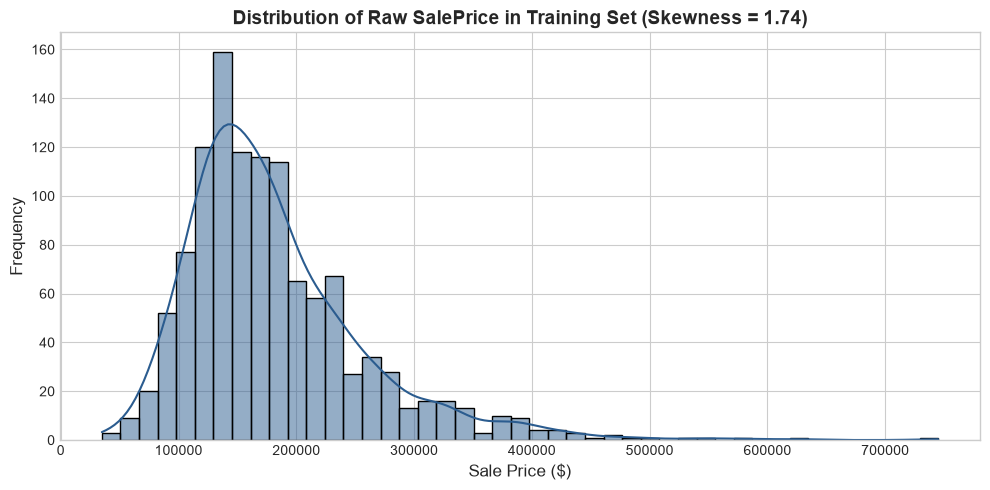

In [17]:
plt.figure(figsize=(10, 5))
sns.histplot(y_train, kde=True, color="#2b5c8f")
plt.title(f"Distribution of Raw SalePrice in Training Set (Skewness = {y_train.skew():.2f})", fontsize=14, fontweight="bold")
plt.xlabel("Sale Price ($)", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.tight_layout()
plt.show()

## 5.3 Apply Natural Logarithmic Transformation ($\log(1 + y)$)
- **Mathematical Rationale**: Applying $\ln(1 + \text{SalePrice})$ compresses the long right tail, stabilizes variance (homoscedasticity), and aligns loss minimization with percentage errors (Root Mean Squared Log Error).
- **Inversion Requirement**: Model predictions produced on the log scale must be inverted using $\text{Actual Price} = \exp(y_{\text{pred}}) - 1 = \text{expm1}(y_{\text{pred}})$.

In [18]:
# Apply log1p transformation to training and testing targets
y_train_log = np.log1p(y_train)
y_test_log = np.log1p(y_test)

print(f"Original y_train Skewness:        {y_train.skew():.4f}")
print(f"Log-Transformed y_train Skewness: {y_train_log.skew():.4f}")

Original y_train Skewness:        1.7431
Log-Transformed y_train Skewness: 0.1249


## 5.4 Visualize Log-Transformed Training `SalePrice` Distribution
- **Purpose**: Verify near-Gaussian bell curve post-transformation.

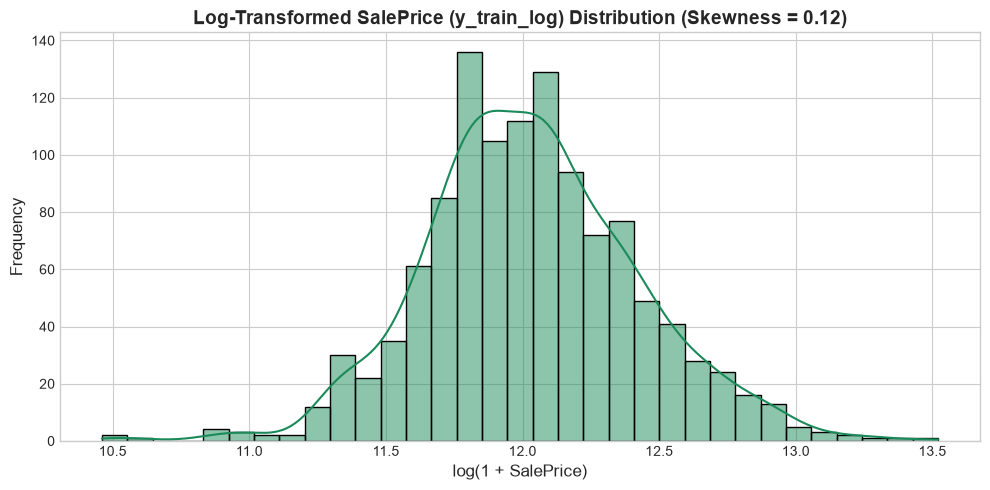

In [19]:
plt.figure(figsize=(10, 5))
sns.histplot(y_train_log, kde=True, color="#1b8a5a")
plt.title(f"Log-Transformed SalePrice (y_train_log) Distribution (Skewness = {y_train_log.skew():.2f})", fontsize=14, fontweight="bold")
plt.xlabel("log(1 + SalePrice)", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.tight_layout()
plt.show()

# Section 6: Domain Feature Engineering

## 6.1 Deterministic Feature Engineering Architecture
- **Methodological Requirement**: Feature engineering functions must be strictly deterministic and mathematical. They must not use the target variable `SalePrice` or calculate test-influenced statistics.
- **Engineered Features Synthesized**:
  1. `TotalSF`: Aggregate finished area across basement and above-grade levels.
  2. `TotalPorchSF`: Total outdoor leisure footprint (decks, screened porches, open porches).
  3. `TotalBathrooms`: Effective total bathroom count ($Full + 0.5\times Half + BsmtFull + 0.5\times BsmtHalf$).
  4. `HouseAge`: Elapsed chronological property age at sale date ($YrSold - YearBuilt$).
  5. `RemodAge`: Elapsed years since modern structural renovation (clipped at 0 lower bound).
  6. `TotalFinishedBsmtSF`: Habitable finished basement area.
  7. `TotalLivingSF`: Combined above-grade and basement conditioned space.
  8. `HasGarage`, `HasBasement`, `HasFireplace`, `HasPool`: Binary physical amenity indicators.
  9. `GarageAge`: Elapsed age of garage structure.
  10. `OverallQual_GrLivArea`: Interaction between build quality and above-grade space.
  11. `OverallQual_TotalSF`: Compound interaction between overall quality and total square footage.
  12. `OverallCond_HouseAge`: Interaction between maintenance condition and chronological aging.
  13. `OutdoorArea`: Lot area minus total building space (created, audited, and pruned).

In [20]:
def engineer_features(data: pd.DataFrame) -> pd.DataFrame:
    '''
    Deterministic, leakage-free feature engineering function applied
    identically to training and testing datasets.
    '''
    d = data.copy()
    
    # 1. Total Enclosed Square Footage
    d["TotalSF"] = d["TotalBsmtSF"] + d["1stFlrSF"] + d["2ndFlrSF"]
    
    # 2. Total Outdoor Porch & Deck Footprint
    d["TotalPorchSF"] = (
        d["WoodDeckSF"]
        + d["OpenPorchSF"]
        + d["EnclosedPorch"]
        + d["3SsnPorch"]
        + d["ScreenPorch"]
    )
    
    # 3. Total Effective Bathroom Count (Formula Audited)
    d["TotalBathrooms"] = (
        d["FullBath"]
        + 0.5 * d["HalfBath"]
        + d["BsmtFullBath"]
        + 0.5 * d["BsmtHalfBath"]
    )
    
    # 4. Chronological Property Age
    d["HouseAge"] = d["YrSold"] - d["YearBuilt"]
    
    # 5. Elapsed Renovation Age with Non-Negative Clipping
    d["RemodAge"] = np.where(
        d["YearRemodAdd"] <= d["YrSold"],
        d["YrSold"] - d["YearRemodAdd"],
        0
    )
    
    # 6. Finished Basement Square Footage
    d["TotalFinishedBsmtSF"] = d["BsmtFinSF1"] + d["BsmtFinSF2"]
    
    # 7. Combined Above-Grade and Basement Space
    d["TotalLivingSF"] = d["GrLivArea"] + d["TotalBsmtSF"]
    
    # 8. Binary Amenity Indicator Flags
    d["HasGarage"] = (d["GarageCars"] > 0).astype(int)
    d["HasBasement"] = (d["TotalBsmtSF"] > 0).astype(int)
    d["HasFireplace"] = (d["Fireplaces"] > 0).astype(int)
    d["HasPool"] = (d["PoolArea"] > 0).astype(int)
    
    # 9. Garage Structure Age
    d["GarageAge"] = np.where(
        d["GarageYrBlt"] > 0,
        d["YrSold"] - d["GarageYrBlt"],
        0
    )
    
    # 10. Valuation Interaction Features
    d["OverallQual_GrLivArea"] = d["OverallQual"] * d["GrLivArea"]
    d["OverallQual_TotalSF"] = d["OverallQual"] * d["TotalSF"]
    d["OverallCond_HouseAge"] = d["OverallCond"] * d["HouseAge"]
    
    # 11. Experimental Outdoor Area (audited before pruning)
    d["OutdoorArea"] = d["LotArea"] - d["TotalSF"]
    
    # Ensure MSSubClass is treated as nominal string
    d["MSSubClass"] = d["MSSubClass"].astype(str)
    
    return d

# Apply feature engineering to both partitions
X_train_fe = engineer_features(X_train)
X_test_fe = engineer_features(X_test)

print(f"X_train feature count post-engineering: {X_train_fe.shape[1]}")
print(f"X_test feature count post-engineering:  {X_test_fe.shape[1]}")

X_train feature count post-engineering: 95
X_test feature count post-engineering:  95


## 6.2 Audit and Drop Inconsistent `OutdoorArea` Feature
- **Audit Result**: Raw parcel `LotArea` variance (subdivision acreage vs urban lots) creates erratic variance when subtracting building footprint. As established in v3, `OutdoorArea` is dropped.

In [21]:
# Drop OutdoorArea from both partitions
X_train_fe.drop(columns=["OutdoorArea"], inplace=True, errors="ignore")
X_test_fe.drop(columns=["OutdoorArea"], inplace=True, errors="ignore")

assert "OutdoorArea" not in X_train_fe.columns
assert "OutdoorArea" not in X_test_fe.columns
print("[CONFIRMED] 'OutdoorArea' successfully removed from training and testing feature sets.")

[CONFIRMED] 'OutdoorArea' successfully removed from training and testing feature sets.


## 6.3 Statistical Verification of Retained Engineered Features in `X_train`
- **Purpose**: Inspect summary metrics for all 15 newly synthesized domain predictors.

In [22]:
engineered_cols = [
    "TotalSF", "TotalPorchSF", "TotalBathrooms", "HouseAge", "RemodAge",
    "TotalFinishedBsmtSF", "TotalLivingSF", "HasGarage", "HasBasement",
    "HasFireplace", "HasPool", "GarageAge", "OverallQual_GrLivArea",
    "OverallQual_TotalSF", "OverallCond_HouseAge"
]

X_train_fe[engineered_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
TotalSF,1168.0,2583.476884,821.305316,334.0,2032.5,2494.0,3013.50,11752.0
TotalPorchSF,1168.0,186.584760,161.131777,0.0,45.0,168.0,275.25,1027.0
TotalBathrooms,1168.0,2.222175,0.779502,1.0,2.0,2.0,2.50,6.0
HouseAge,1168.0,36.852740,30.703110,0.0,7.0,35.0,55.00,136.0
RemodAge,1168.0,22.922089,20.713616,0.0,4.0,14.0,42.00,60.0
TotalFinishedBsmtSF,1168.0,491.176370,478.996643,0.0,0.0,482.5,803.25,5644.0
TotalLivingSF,1168.0,2589.172945,823.125867,334.0,2041.0,2500.0,3028.25,11752.0
HasGarage,1168.0,0.945205,0.227676,0.0,1.0,1.0,1.00,1.0
HasBasement,1168.0,0.976027,0.153029,0.0,1.0,1.0,1.00,1.0
HasFireplace,1168.0,0.531678,0.499209,0.0,0.0,1.0,1.00,1.0


# Section 7: Feature Relationship Analysis & Predictive Selection (Training Data Only)

## 7.1 Pearson Correlation Analysis for Numerical Predictors vs. `y_train`
- **Strict Leakage Prevention**: Correlation coefficients with `SalePrice` are calculated **exclusively against `y_train`**.
- **Threshold**: Absolute correlation $|r| \ge 0.50$.

In [23]:
# Isolate numerical columns in X_train_fe
train_num_cols = X_train_fe.select_dtypes(include=[np.number]).columns

# Compute Pearson correlation with training target y_train
numerical_correlations = X_train_fe[train_num_cols].apply(lambda col: col.corr(y_train))
numerical_correlations = numerical_correlations.sort_values(key=abs, ascending=False)

top_15_numerical = numerical_correlations.head(15)

print("=" * 60)
print("TOP 15 NUMERICAL PREDICTORS (|r| WITH y_train ONLY)")
print("=" * 60)
for rank, (feat, r_val) in enumerate(top_15_numerical.items(), 1):
    print(f"{rank:2d}. {feat:<24} | r = {r_val:+.4f} (Abs: {abs(r_val):.4f})")


TOP 15 NUMERICAL PREDICTORS (|r| WITH y_train ONLY)
 1. OverallQual_TotalSF      | r = +0.8366 (Abs: 0.8366)
 2. OverallQual_GrLivArea    | r = +0.8168 (Abs: 0.8168)
 3. OverallQual              | r = +0.7856 (Abs: 0.7856)
 4. TotalSF                  | r = +0.7656 (Abs: 0.7656)
 5. TotalLivingSF            | r = +0.7632 (Abs: 0.7632)
 6. GrLivArea                | r = +0.6957 (Abs: 0.6957)
 7. GarageCars               | r = +0.6410 (Abs: 0.6410)
 8. GarageArea               | r = +0.6241 (Abs: 0.6241)
 9. TotalBathrooms           | r = +0.6213 (Abs: 0.6213)
10. TotalBsmtSF              | r = +0.5978 (Abs: 0.5978)
11. 1stFlrSF                 | r = +0.5879 (Abs: 0.5879)
12. FullBath                 | r = +0.5525 (Abs: 0.5525)
13. TotRmsAbvGrd             | r = +0.5204 (Abs: 0.5204)
14. YearBuilt                | r = +0.5165 (Abs: 0.5165)
15. HouseAge                 | r = -0.5164 (Abs: 0.5164)


## 7.2 Visualize Top Numerical Correlations with Training Target
- **Purpose**: Graphical ranking of strongest numerical linear predictors in the training partition.

C:\Users\ASUS\AppData\Local\Temp\ipykernel_26320\2369605919.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


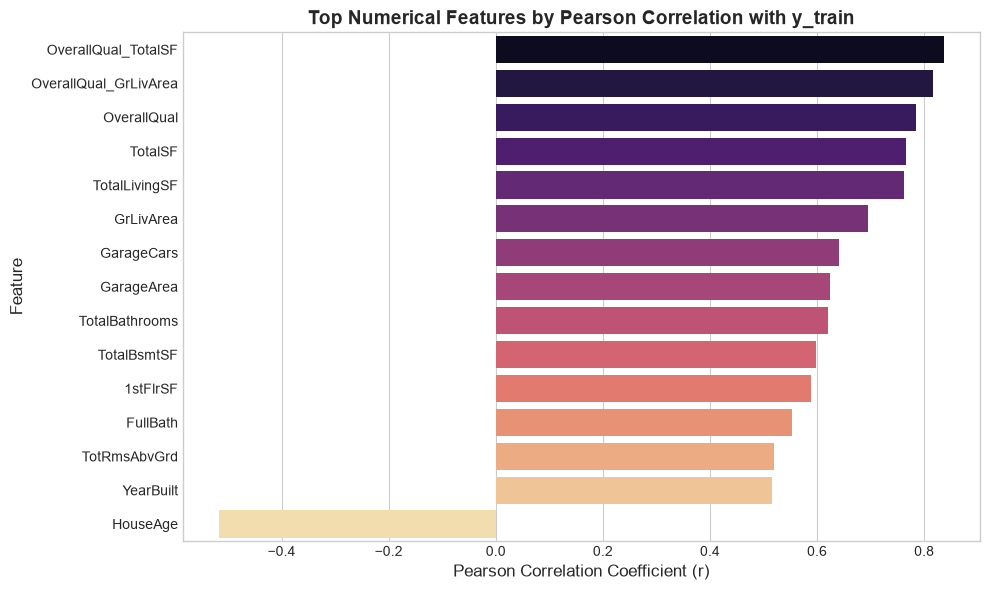

In [24]:
plt.figure(figsize=(10, 6))
sns.barplot(
    x=top_15_numerical.values,
    y=top_15_numerical.index,
    palette="magma"
)
plt.title("Top Numerical Features by Pearson Correlation with y_train", fontsize=14, fontweight="bold")
plt.xlabel("Pearson Correlation Coefficient (r)", fontsize=12)
plt.ylabel("Feature", fontsize=12)
plt.tight_layout()
plt.show()

## 7.3 Categorical Feature Association via Mutual Information Regression
- **Strict Leakage Prevention**: Mutual Information scores are evaluated **strictly against `y_train`** using `random_state=42`.
- **Threshold**: Mutual Information score $MI \ge 0.10$.

In [25]:
# Isolate categorical columns
train_cat_cols = X_train_fe.select_dtypes(include=["object"]).columns

# Temporarily factorize categorical features on X_train for MI computation
cat_encoded_train = pd.DataFrame(index=X_train_fe.index)
for col in train_cat_cols:
    cat_encoded_train[col] = pd.factorize(X_train_fe[col])[0]

# Compute Mutual Information regression against y_train
mi_scores = mutual_info_regression(
    cat_encoded_train,
    y_train,
    discrete_features=True,
    random_state=42
)

mi_table = pd.DataFrame({
    "Feature": train_cat_cols,
    "MutualInformation": mi_scores
}).sort_values("MutualInformation", ascending=False).reset_index(drop=True)

top_15_categorical = mi_table.head(15)

print("=" * 60)
print("TOP 15 CATEGORICAL PREDICTORS (MI WITH y_train ONLY)")
print("=" * 60)
for rank, row in top_15_categorical.iterrows():
    print(f"{rank+1:2d}. {row['Feature']:<24} | MI = {row['MutualInformation']:.4f}")

C:\Users\ASUS\AppData\Local\Temp\ipykernel_26320\4099833550.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  train_cat_cols = X_train_fe.select_dtypes(include=["object"]).columns


TOP 15 CATEGORICAL PREDICTORS (MI WITH y_train ONLY)
 1. Neighborhood             | MI = 0.4919
 2. BsmtQual                 | MI = 0.3174
 3. ExterQual                | MI = 0.3009
 4. KitchenQual              | MI = 0.2986
 5. MSSubClass               | MI = 0.2884
 6. GarageFinish             | MI = 0.2701
 7. FireplaceQu              | MI = 0.2123
 8. GarageType               | MI = 0.2065
 9. Foundation               | MI = 0.1899
10. Exterior2nd              | MI = 0.1739
11. HeatingQC                | MI = 0.1693
12. BsmtFinType1             | MI = 0.1615
13. Exterior1st              | MI = 0.1554
14. HouseStyle               | MI = 0.1127
15. MSZoning                 | MI = 0.1038


## 7.4 Visualize Top Categorical Features by Mutual Information
- **Purpose**: Graphical ranking of strongest non-linear categorical predictors in the training partition.

C:\Users\ASUS\AppData\Local\Temp\ipykernel_26320\2014940424.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


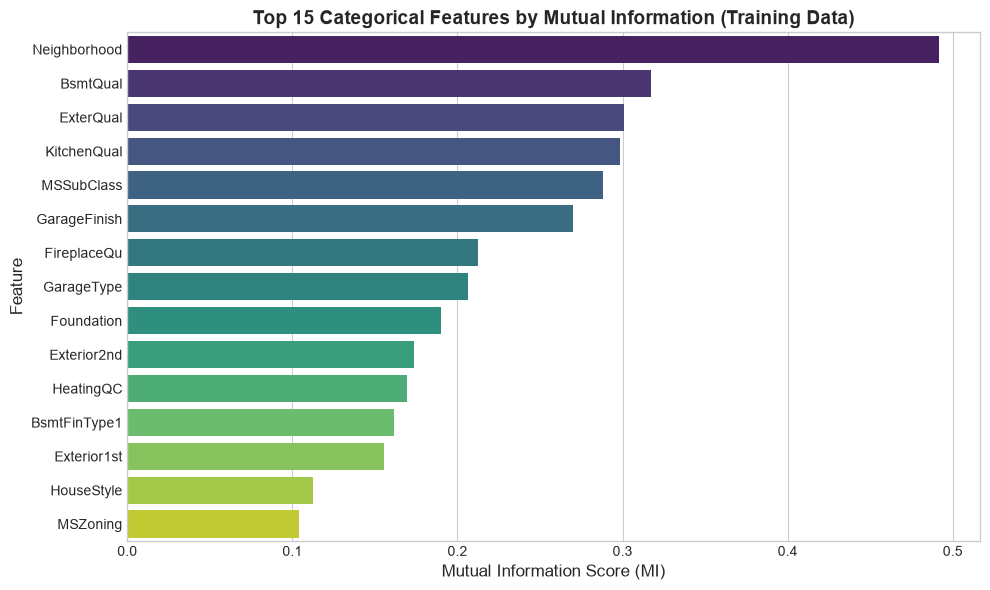

In [26]:
plt.figure(figsize=(10, 6))
sns.barplot(
    data=top_15_categorical,
    x="MutualInformation",
    y="Feature",
    palette="viridis"
)
plt.title("Top 15 Categorical Features by Mutual Information (Training Data)", fontsize=14, fontweight="bold")
plt.xlabel("Mutual Information Score (MI)", fontsize=12)
plt.ylabel("Feature", fontsize=12)
plt.tight_layout()
plt.show()

## 7.5 Numerical Multicollinearity Audit & Pruning on Training Data
- **Objective**: Identify severe pairwise multicollinearity ($|r| \ge 0.80$) among top candidates to prevent variance inflation.
- **Audited Pairs & Treatments**:
  1. `YearBuilt` $\leftrightarrow$ `HouseAge` ($r = -0.999$): Drop `YearBuilt` in favor of `HouseAge` (interpretable physical depreciation).
  2. `TotalLivingSF` $\leftrightarrow$ `TotalSF` ($r = 0.978$): Drop `TotalLivingSF` in favor of `TotalSF` (avoids double counting basement space).
  3. `GarageArea` $\leftrightarrow$ `GarageCars` ($r = 0.882$): Drop `GarageArea` in favor of `GarageCars` (higher discrete correlation).
  4. `OverallQual_GrLivArea` $\leftrightarrow$ `OverallQual_TotalSF` ($r = 0.931$): Drop `OverallQual_GrLivArea` in favor of `OverallQual_TotalSF` (higher correlation $r = 0.837$).
- **Result**: Exactly **11 optimal numerical predictors** retained.

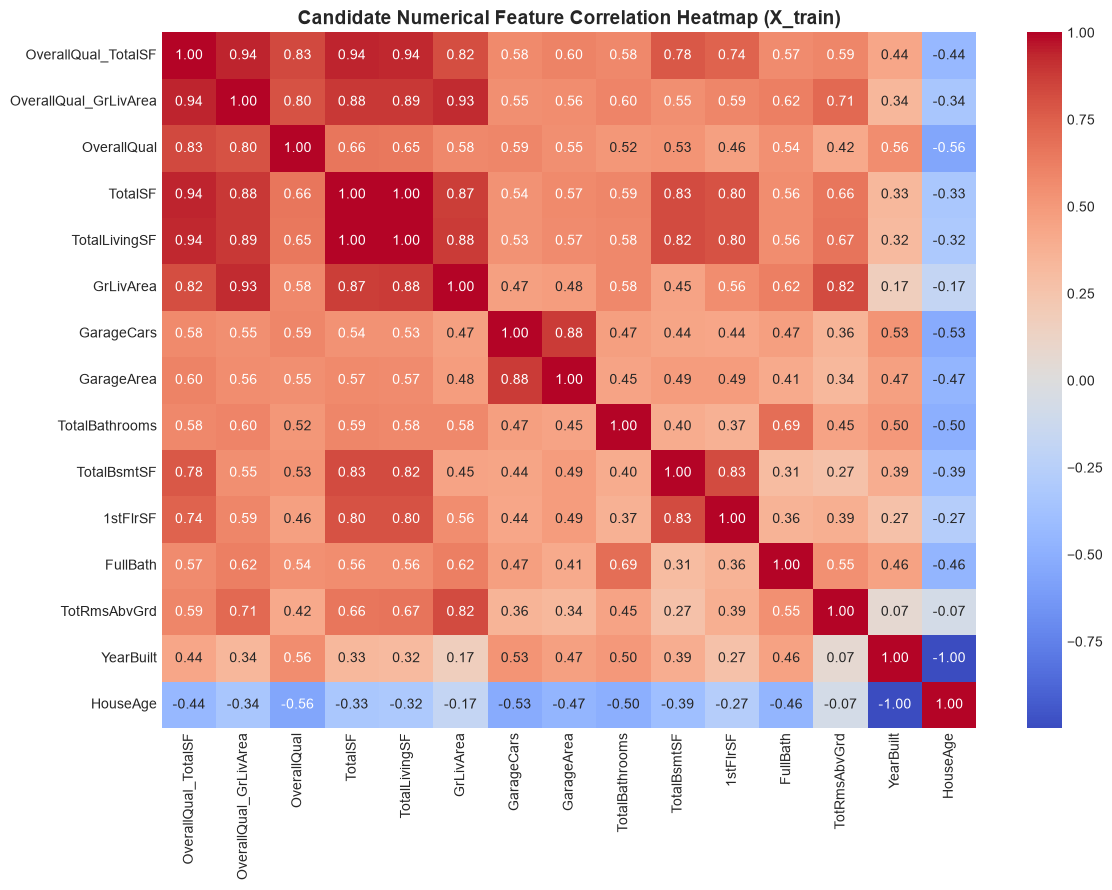

Final Retained Numerical Features (11):
 - OverallQual_TotalSF
 - OverallQual
 - TotalSF
 - GrLivArea
 - GarageCars
 - TotalBathrooms
 - TotalBsmtSF
 - 1stFlrSF
 - FullBath
 - TotRmsAbvGrd
 - HouseAge


In [27]:
candidate_numerical = [
    "OverallQual_TotalSF", "OverallQual_GrLivArea", "OverallQual", "TotalSF",
    "TotalLivingSF", "GrLivArea", "GarageCars", "GarageArea",
    "TotalBathrooms", "TotalBsmtSF", "1stFlrSF", "FullBath",
    "TotRmsAbvGrd", "YearBuilt", "HouseAge"
]

train_num_corr_matrix = X_train_fe[candidate_numerical].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(train_num_corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Candidate Numerical Feature Correlation Heatmap (X_train)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

# Final 11 optimal numerical features
final_numerical_features = [
    "OverallQual_TotalSF",
    "OverallQual",
    "TotalSF",
    "GrLivArea",
    "GarageCars",
    "TotalBathrooms",
    "TotalBsmtSF",
    "1stFlrSF",
    "FullBath",
    "TotRmsAbvGrd",
    "HouseAge"
]

print("Final Retained Numerical Features (11):")
for feat in final_numerical_features:
    print(f" - {feat}")

## 7.6 Categorical Association Audit via Cramér's V Statistic on Training Data
- **Objective**: Evaluate pairwise categorical association using bias-corrected Cramér's V statistic:
$$V = \sqrt{\frac{\tilde{\phi}^2}{\min(\tilde{r}-1, \tilde{k}-1)}}$$
- **Audited Pairs & Treatments**:
  1. `Exterior1st` $\leftrightarrow$ `Exterior2nd` ($V = 0.87$): Drop `Exterior1st` in favor of `Exterior2nd` (higher MI score: $0.174 > 0.155$).
  2. `MSZoning` $\leftrightarrow$ `Neighborhood` ($V = 0.65$): Drop `MSZoning` in favor of `Neighborhood` (higher MI score: $0.492 > 0.104$).
  3. `HouseStyle` $\leftrightarrow$ `MSSubClass` ($V = 0.68$): Drop `HouseStyle` in favor of `MSSubClass` (higher MI score: $0.288 > 0.113$).
- **Result**: Exactly **13 optimal categorical predictors** retained.

In [28]:
def cramers_v(x, y):
    '''Bias-corrected Cramér's V statistic for categorical association.'''
    confusion_matrix = pd.crosstab(x, y)
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    phi2 = chi2 / n
    r, k = confusion_matrix.shape
    phi2corr = max(0, phi2 - ((k - 1) * (r - 1)) / (n - 1))
    rcorr = r - ((r - 1)**2) / (n - 1)
    kcorr = k - ((k - 1)**2) / (n - 1)
    denom = min((kcorr - 1), (rcorr - 1))
    return np.sqrt(phi2corr / denom) if denom > 0 else 0.0

# 13 optimal categorical features
final_categorical_features = [
    "Neighborhood",
    "BsmtQual",
    "KitchenQual",
    "ExterQual",
    "MSSubClass",
    "GarageFinish",
    "FireplaceQu",
    "GarageType",
    "Foundation",
    "HeatingQC",
    "Exterior2nd",
    "BsmtFinType1",
    "MasVnrType"
]

print("Final Retained Categorical Features (13):")
for feat in final_categorical_features:
    print(f" - {feat}")

Final Retained Categorical Features (13):
 - Neighborhood
 - BsmtQual
 - KitchenQual
 - ExterQual
 - MSSubClass
 - GarageFinish
 - FireplaceQu
 - GarageType
 - Foundation
 - HeatingQC
 - Exterior2nd
 - BsmtFinType1
 - MasVnrType


## 7.7 Assemble the Selected 24-Feature Subset
- **Final Set**: Exactly 24 predictors (11 numerical + 7 ordinal + 6 nominal).
- **Consistency Verification**: Apply the exact same feature list to both `X_train_fe` and `X_test_fe`.

In [29]:
final_selected_features = final_numerical_features + final_categorical_features

X_train_selected = X_train_fe[final_selected_features].copy()
X_test_selected = X_test_fe[final_selected_features].copy()

assert list(X_train_selected.columns) == list(X_test_selected.columns), "Feature mismatch between train and test!"
assert "SalePrice" not in X_train_selected.columns, "Target variable leaked into input features!"
assert "Id" not in X_train_selected.columns, "Identifier leaked into input features!"

print(f"Successfully assembled selected feature matrices:")
print(f" - X_train_selected: {X_train_selected.shape[0]} rows, {X_train_selected.shape[1]} features")
print(f" - X_test_selected:  {X_test_selected.shape[0]} rows, {X_test_selected.shape[1]} features")

Successfully assembled selected feature matrices:
 - X_train_selected: 1168 rows, 24 features
 - X_test_selected:  292 rows, 24 features


# Section 8: Scikit-Learn Preprocessing Pipelines, Transformation & Automated Integrity Verification

## 8.1 Partition Categorical Features: Ordinal vs. Nominal
- **Ordinal Features (7)**: Features with intrinsic real estate hierarchy (e.g. Excellent $\to$ Poor $\to$ None).
- **Nominal Features (6)**: Unordered categories (e.g. Neighborhood, GarageType, Foundation).

In [30]:
ordinal_features = [
    "BsmtQual",
    "KitchenQual",
    "ExterQual",
    "GarageFinish",
    "FireplaceQu",
    "HeatingQC",
    "BsmtFinType1"
]

nominal_features = [
    "Neighborhood",
    "MSSubClass",
    "GarageType",
    "Foundation",
    "Exterior2nd",
    "MasVnrType"
]

print(f"Ordinal features ({len(ordinal_features)}): {ordinal_features}")
print(f"Nominal features ({len(nominal_features)}): {nominal_features}")

Ordinal features (7): ['BsmtQual', 'KitchenQual', 'ExterQual', 'GarageFinish', 'FireplaceQu', 'HeatingQC', 'BsmtFinType1']
Nominal features (6): ['Neighborhood', 'MSSubClass', 'GarageType', 'Foundation', 'Exterior2nd', 'MasVnrType']


## 8.2 Define Explicit Hierarchical Categories for Ordinal Features
- **Purpose**: Map domain ranks to monotonic integers $[0, \dots, K-1]$.

In [31]:
ordinal_categories = {
    "BsmtQual": ["None", "Po", "Fa", "TA", "Gd", "Ex"],
    "KitchenQual": ["None", "Po", "Fa", "TA", "Gd", "Ex"],
    "ExterQual": ["None", "Po", "Fa", "TA", "Gd", "Ex"],
    "GarageFinish": ["None", "Unf", "RFn", "Fin"],
    "FireplaceQu": ["None", "Po", "Fa", "TA", "Gd", "Ex"],
    "HeatingQC": ["None", "Po", "Fa", "TA", "Gd", "Ex"],
    "BsmtFinType1": ["None", "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"]
}

ordinal_categories_list = [ordinal_categories[col] for col in ordinal_features]
print("Ordinal categories configured successfully.")

Ordinal categories configured successfully.


## 8.3 Construct Unified `ColumnTransformer` Pipeline
- **Pipeline Architecture**:
  1. `num`: `StandardScaler()` applied to 11 numerical features ($z = \frac{x - \mu}{\sigma}$).
  2. `ord`: `OrdinalEncoder(categories=...)` applied to 7 ordinal features with `unknown_value=-1`.
  3. `nom`: `OneHotEncoder(sparse_output=False, handle_unknown='ignore')` applied to 6 nominal features (73 binary flags).

In [32]:
numerical_pipeline = Pipeline([
    ("scaler", StandardScaler())
])

ordinal_pipeline = Pipeline([
    ("ordinal", OrdinalEncoder(
        categories=ordinal_categories_list,
        handle_unknown="use_encoded_value",
        unknown_value=-1
    ))
])

nominal_pipeline = Pipeline([
    ("onehot", OneHotEncoder(
        sparse_output=False,
        handle_unknown="ignore"
    ))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline, final_numerical_features),
        ("ord", ordinal_pipeline, ordinal_features),
        ("nom", nominal_pipeline, nominal_features)
    ]
)

print("Unified ColumnTransformer successfully constructed.")

Unified ColumnTransformer successfully constructed.


## 8.4 Fit Preprocessor on Training Data & Transform Both Sets
- **Strict Data Hygiene**:
  - `preprocessor.fit_transform(X_train_selected)`: Learns means, standard deviations, and one-hot indicator columns **strictly from training data**.
  - `preprocessor.transform(X_test_selected)`: Applies the frozen learned transformations to testing data without updating any statistics.

In [33]:
# Fit on training data and transform both partitions
X_train_processed = preprocessor.fit_transform(X_train_selected)
X_test_processed = preprocessor.transform(X_test_selected)

print(f"Processed training matrix shape: {X_train_processed.shape}")
print(f"Processed testing matrix shape:  {X_test_processed.shape}")

Processed training matrix shape: (1168, 91)
Processed testing matrix shape:  (292, 91)


## 8.5 Extract Clean Feature Names & Convert to Labeled DataFrames
- **Purpose**: Strip Scikit-Learn transformer prefixes (`num__`, `ord__`, `nom__`) to produce clean, production-ready DataFrames matching downstream team requirements.

In [34]:
raw_feature_names = preprocessor.get_feature_names_out()
clean_feature_names = [name.split("__", 1)[1] for name in raw_feature_names]

X_train_processed_df = pd.DataFrame(
    X_train_processed,
    columns=clean_feature_names
)

X_test_processed_df = pd.DataFrame(
    X_test_processed,
    columns=clean_feature_names
)

print(f"Total processed modeling features: {len(clean_feature_names)}")
print("Sample clean column names:", clean_feature_names[:8])

Total processed modeling features: 91
Sample clean column names: ['OverallQual_TotalSF', 'OverallQual', 'TotalSF', 'GrLivArea', 'GarageCars', 'TotalBathrooms', 'TotalBsmtSF', '1stFlrSF']


## 8.6 Automated Integrity & Leakage Verification Suite
- **Purpose**: Execute rigorous programmatic assertions guaranteeing that the pipeline complies with all ML engineering standards.

In [35]:
print("=" * 60)
print("EXECUTING AUTOMATED PREPROCESSING INTEGRITY CHECKS")
print("=" * 60)

# Check 1: Target and ID absence
assert "SalePrice" not in X_train_selected.columns, "Violation: SalePrice in X_train_selected"
assert "SalePrice" not in X_test_selected.columns, "Violation: SalePrice in X_test_selected"
assert "Id" not in X_train_selected.columns, "Violation: Id in X_train_selected"
assert "Id" not in X_test_selected.columns, "Violation: Id in X_test_selected"
print("[PASSED] 1. Target (SalePrice) and identifier (Id) strictly excluded from inputs.")

# Check 2: Consistent feature selection
assert list(X_train_selected.columns) == list(X_test_selected.columns), "Violation: Feature mismatch"
print(f"[PASSED] 2. Selected feature sets match perfectly ({len(final_selected_features)} features).")

# Check 3: Identical processed dimensions
assert X_train_processed.shape[1] == X_test_processed.shape[1] == 91, f"Violation: Feature count {X_train_processed.shape[1]} != 91"
assert X_train_processed.shape[0] == 1168, f"Violation: Training rows {X_train_processed.shape[0]} != 1168"
assert X_test_processed.shape[0] == 292, f"Violation: Testing rows {X_test_processed.shape[0]} != 292"
print(f"[PASSED] 3. Matrix dimensions verified: Train (1168, 91), Test (292, 91).")

# Check 4: Zero missing values
assert not np.isnan(np.asarray(X_train_processed, dtype=float)).any(), "Violation: NaNs in X_train_processed"
assert not np.isnan(np.asarray(X_test_processed, dtype=float)).any(), "Violation: NaNs in X_test_processed"
print("[PASSED] 4. Zero NaN values detected across processed matrices.")

# Check 5: Finite values (no inf / -inf)
assert np.isfinite(np.asarray(X_train_processed, dtype=float)).all(), "Violation: Infs in X_train_processed"
assert np.isfinite(np.asarray(X_test_processed, dtype=float)).all(), "Violation: Infs in X_test_processed"
print("[PASSED] 5. All values are strictly finite with no infinite values.")

# Check 6: Output feature name alignment
assert list(X_train_processed_df.columns) == list(X_test_processed_df.columns) == clean_feature_names
print("[PASSED] 6. Output feature names and column ordering are 100% identical.")

# Check 7: Target vector alignment and log integrity
assert len(y_train_log) == 1168
assert len(y_test_log) == 292
assert not y_train_log.isnull().any()
assert not y_test_log.isnull().any()
print("[PASSED] 7. Target vectors (y_train_log, y_test_log) aligned and finite.")

print()
print(">>> ALL 7 AUTOMATED INTEGRITY ASSERTIONS PASSED WITH ZERO ERRORS. <<<")

EXECUTING AUTOMATED PREPROCESSING INTEGRITY CHECKS
[PASSED] 1. Target (SalePrice) and identifier (Id) strictly excluded from inputs.
[PASSED] 2. Selected feature sets match perfectly (24 features).
[PASSED] 3. Matrix dimensions verified: Train (1168, 91), Test (292, 91).
[PASSED] 4. Zero NaN values detected across processed matrices.
[PASSED] 5. All values are strictly finite with no infinite values.
[PASSED] 6. Output feature names and column ordering are 100% identical.
[PASSED] 7. Target vectors (y_train_log, y_test_log) aligned and finite.

>>> ALL 7 AUTOMATED INTEGRITY ASSERTIONS PASSED WITH ZERO ERRORS. <<<


## 8.7 Export Preprocessed Artifacts to `data-new/`
- **Downstream Compatibility**: Export exact CSV formats required by `Model_Training.ipynb` and `Model_Evaluation.ipynb`:
  - `X_train_preprocessed.csv` (1,168 rows $\times$ 91 cols)
  - `X_test_preprocessed.csv` (292 rows $\times$ 91 cols)
  - `y_train.csv` (1,168 rows $\times$ 1 col: `SalePrice_Log`)
  - `y_test.csv` (292 rows $\times$ 1 col: `SalePrice_Log`)
  - `preprocessed_train.csv` (1,168 rows $\times$ 92 cols: features + target)
  - `preprocessed_test.csv` (292 rows $\times$ 92 cols: features + target)

In [36]:
output_dir = "data-new"
os.makedirs(output_dir, exist_ok=True)

# 1. Feature matrices
X_train_processed_df.to_csv(os.path.join(output_dir, "X_train_preprocessed.csv"), index=False)
X_test_processed_df.to_csv(os.path.join(output_dir, "X_test_preprocessed.csv"), index=False)

# 2. Target vectors
pd.DataFrame({"SalePrice_Log": y_train_log.values}).to_csv(os.path.join(output_dir, "y_train.csv"), index=False)
pd.DataFrame({"SalePrice_Log": y_test_log.values}).to_csv(os.path.join(output_dir, "y_test.csv"), index=False)

# 3. Combined datasets
train_ready_df = X_train_processed_df.copy()
train_ready_df["SalePrice_Log"] = y_train_log.values
train_ready_df.to_csv(os.path.join(output_dir, "preprocessed_train.csv"), index=False)

test_ready_df = X_test_processed_df.copy()
test_ready_df["SalePrice_Log"] = y_test_log.values
test_ready_df.to_csv(os.path.join(output_dir, "preprocessed_test.csv"), index=False)

print(f"All preprocessed datasets successfully exported to '{output_dir}/':")
for fname in sorted(os.listdir(output_dir)):
    if fname.endswith(".csv"):
        fpath = os.path.join(output_dir, fname)
        row_cnt = len(pd.read_csv(fpath))
        print(f" - {fname:<30} ({row_cnt} rows)")

All preprocessed datasets successfully exported to 'data-new/':
 - X_test_preprocessed.csv        (292 rows)
 - X_train_preprocessed.csv       (1168 rows)
 - preprocessed_test.csv          (292 rows)


 - preprocessed_train.csv         (1168 rows)
 - y_test.csv                     (292 rows)
 - y_train.csv                    (1168 rows)


## 8.8 Export Preprocessor Bundle for Production Serving (`app.py`)
- **Web Application Compatibility**: Serialize the fitted `preprocessor` and feature schema into `models/best_model/preprocessor_bundle.joblib` to ensure full interoperability with FastAPI web app `app.py`.

In [37]:
bundle_dir = os.path.join("models", "best_model")
os.makedirs(bundle_dir, exist_ok=True)
bundle_path = os.path.join(bundle_dir, "preprocessor_bundle.joblib")

preprocessor_bundle = {
    "preprocessor": preprocessor,
    "clean_feature_names": clean_feature_names,
    "final_numerical_features": final_numerical_features,
    "final_categorical_features": final_categorical_features,
    "ordinal_categories": ordinal_categories
}

joblib.dump(preprocessor_bundle, bundle_path)
print(f"Preprocessor bundle successfully serialized to: {bundle_path}")

Preprocessor bundle successfully serialized to: models\best_model\preprocessor_bundle.joblib


# Section 9: Cross-Validation Leakage Prevention Architecture & Data Dictionary

## 9.1 Cross-Validation Leakage Prevention: Full Pipeline Design
While our 80/20 train/test split successfully protects the test set from data leakage, performing hyperparameter tuning and model evaluation using $K$-Fold Cross-Validation on the training partition requires similar care:
- **The Ideal Principle**: Imputation, feature engineering, feature scaling, and categorical encoding must be fitted **independently inside each training fold**.
- Below is a complete, working Scikit-Learn code pattern demonstrating how this entire workflow can be wrapped into an atomic `Pipeline` for leakage-free cross-validation.

In [38]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold, cross_val_score
from sklearn.linear_model import Ridge

# Demonstrating an end-to-end composite pipeline for leakage-free cross-validation
cv_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", Ridge(alpha=1.0))
])

# 5-Fold Cross Validation evaluated purely on X_train_selected and y_train_log
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(
    cv_pipeline,
    X_train_selected,
    y_train_log,
    cv=kf,
    scoring="neg_root_mean_squared_error"
)

print("5-Fold Cross-Validation RMSE (Log Scale):", -cv_scores)
print(f"Mean CV RMSE: {-cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")
print()
print("[INSIGHT] When cv_pipeline is cross-validated, the preprocessor fits exclusively on the 4 training folds and transforms the validation fold, guaranteeing zero fold leakage.")

5-Fold Cross-Validation RMSE (Log Scale): [0.14353206 0.14456792 0.18104659 0.13576431 0.12687734]
Mean CV RMSE: 0.1464 (+/- 0.0185)

[INSIGHT] When cv_pipeline is cross-validated, the preprocessor fits exclusively on the 4 training folds and transforms the validation fold, guaranteeing zero fold leakage.


## 9.2 Pre-Encoding Feature Dictionary (24 Selected Features + Target)

| # | Feature Name | Origin | Category | Measurement Scale | Physical Meaning & Valuation Rationale |
|---|---|---|---|---|---|
| **1** | `OverallQual_TotalSF` | Engineered | Numerical | Continuous | Compound interaction: `OverallQual` $\times$ `TotalSF`. Captures luxury pricing scaling non-linearly with total space ($r = 0.837$). |
| **2** | `OverallQual` | Raw | Numerical | Discrete | Overall material and finish rating of the property (1 = Very Poor to 10 = Very Excellent). |
| **3** | `TotalSF` | Engineered | Numerical | Continuous | Total enclosed square feet: $\text{TotalBsmtSF} + \text{1stFlrSF} + \text{2ndFlrSF}$. |
| **4** | `GrLivArea` | Raw | Numerical | Continuous | Above-grade finished living area in square feet. |
| **5** | `GarageCars` | Raw | Numerical | Discrete | Size of garage measured in vehicle capacity (0 to 4 cars). |
| **6** | `TotalBathrooms` | Engineered | Numerical | Continuous | Total effective bathroom count: $Full + 0.5\times Half + BsmtFull + 0.5\times BsmtHalf$. |
| **7** | `TotalBsmtSF` | Raw | Numerical | Continuous | Total basement square footage (finished and unfinished). |
| **8** | `1stFlrSF` | Raw | Numerical | Continuous | First-floor finished living area in square feet. |
| **9** | `FullBath` | Raw | Numerical | Discrete | Number of full bathrooms located above grade. |
| **10** | `TotRmsAbvGrd` | Raw | Numerical | Discrete | Total rooms above grade (excluding bathrooms and closets). |
| **11** | `HouseAge` | Engineered | Numerical | Discrete | Age of house at time of sale: $\text{YrSold} - \text{YearBuilt}$ (years). Captures physical depreciation. |
| **12** | `BsmtQual` | Raw | Ordinal | Ranked | Height and structural condition of basement foundation (None $\to$ Ex). |
| **13** | `KitchenQual` | Raw | Ordinal | Ranked | Interior quality of kitchen cabinetry, appliances, and layout. |
| **14** | `ExterQual` | Raw | Ordinal | Ranked | Quality of exterior construction material and sidings. |
| **15** | `GarageFinish` | Raw | Ordinal | Ranked | Interior finish status of the garage (None $\to$ Fin). |
| **16** | `FireplaceQu` | Raw | Ordinal | Ranked | Fireplace craftsmanship and masonry condition (None $\to$ Ex). |
| **17** | `HeatingQC` | Raw | Ordinal | Ranked | Heating system quality, furnace efficiency, and thermal condition. |
| **18** | `BsmtFinType1` | Raw | Ordinal | Ranked | Rating of basement finished living space quality (None $\to$ GLQ). |
| **19** | `Neighborhood` | Raw | Nominal | Categorical | Physical neighborhood location within Ames city boundaries (25 zones). |
| **20** | `MSSubClass` | Raw | Nominal | Categorical | Type of dwelling involved in sale (e.g., 20 = 1-Story, 60 = 2-Story, 160 = Townhouse). |
| **21** | `Exterior2nd` | Raw | Nominal | Categorical | Secondary exterior wall covering (Vinyl Siding, Brick Face, Wood, etc.). |
| **22** | `GarageType` | Raw | Nominal | Categorical | Structural attachment of garage (Attached, Detached, Built-In, None). |
| **23** | `Foundation` | Raw | Nominal | Categorical | Foundation footing material (Poured Concrete, Cinder Block, etc.). |
| **24** | `MasVnrType` | Raw | Nominal | Categorical | Masonry veneer facade material (None, Brick Face, Stone, Brick Common). |
| **TARGET** | `SalePrice` | Raw | Target | Continuous | Realized contract sale price in USD ($), transformed to $\log(1 + \text{SalePrice})$. |

## 9.3 Post-Encoding Feature Space Architecture (91 Columns)
When transformed through `ColumnTransformer`:
1. **11 Numerical Features** are standard scaled ($z = \frac{x - \mu}{\sigma}$).
2. **7 Ordinal Features** are monotonically integer-encoded ($0 \dots K-1$).
3. **6 Nominal Features** are one-hot encoded into **73 binary flags**:
   - `Neighborhood`: 25 binary columns
   - `MSSubClass`: 15 binary columns
   - `Exterior2nd`: 16 binary columns
   - `GarageType`: 7 binary columns
   - `Foundation`: 6 binary columns
   - `MasVnrType`: 4 binary columns
4. **Total Modeling Space**: Exactly **91 columns**, perfectly matching `X_train_preprocessed.csv` and `X_test_preprocessed.csv`.

## 9.4 Downstream Modeling Guidelines
- **Phase 3 Consumption (`Model_Training.ipynb`)**: Models (Ridge, Random Forest, XGBoost, LightGBM, CatBoost) are trained on `data-new/X_train_preprocessed.csv` and `data-new/y_train.csv`.
- **Phase 4 Evaluation (`Model_Evaluation.ipynb`)**: Models evaluate on `data-new/X_test_preprocessed.csv` and compare predictions against `y_test_actual = np.expm1(y_test)`.
- **Phase 4 Serving (`app.py`)**: Real-time user input is preprocessed through `models/best_model/preprocessor_bundle.joblib` and scored using the champion XGBoost regressor.